## make very toy data

## notes:
- The pixel scale is anisotropic, apparently?
- What size are the 2-d images?
- Notation is w,z is the coordinate system in the data images.

In [1]:
import numpy as np
import pylab as plt
import os
import scipy.special as special
from astropy.table import Table
from astropy.io import fits

In [2]:
rng = np.random.default_rng(19) # the most random number
SQRT2PI = np.sqrt(2. * np.pi)
WPIXSCALE = 0.059 # arcsec
ZPIXSCALE = 3. * WPIXSCALE
N, Nw, Nz = 120, 18, 12 # this seems wrong, but Hogg has read a lot of documentation

In [3]:
def choose_xy(rng, rad=0.59):
    xy = np.inf, np.inf
    while np.linalg.norm(xy) > rad:
        xy = rad * (2. * rng.uniform(size=2) - 1.)
    return xy

def oned_gaussian(xs, mu, sigma=1.):
    return (1. / (SQRT2PI * sigma)) * np.exp(-0.5 * ((xs - mu) / sigma) ** 2)

def rotscale(psi):
    """
    ## input:
    - `psi`: a scan angle

    ## output:
    - the 2x2 operator that transforms an x,y displacement on the sky to a w,z displacement on the device

    ## comments:
    - The pixels aren't square, goddamn it.

    ## bugs:
    - Hard-coded magic pixel scales.
    """
    cp, sp = np.cos(psi), np.sin(psi)
    return np.array([[cp / WPIXSCALE, sp / WPIXSCALE], [-sp / ZPIXSCALE, cp / ZPIXSCALE]])

def make_one_toy_dataset(rng):
    """
    ## inputs:
    - `rng`: A numpy random number generator

    ## outputs:
    - `X`: A table of housekeeping data
    - `Y`: A set of Gaia-like images
    - `truth`: A table of true information about the scene
    
    ## bugs:
    - Everything is hard-coded.
    - Cadence, scan-angle distribution, CCD numbers, are all unrealistically uncorrelated, and thus this is too easy.
    """
    Nstars = 0
    while Nstars < 1:
        Nstars = rng.poisson(1.5) # magic
    # print(Nstars)
    truth = Table()
    truth["flux"] = np.sort(1. + 10. * rng.uniform(size=Nstars) ** 2)[::-1] # so much magic
    truth["xy"] = np.atleast_2d([np.zeros(2), ] + [choose_xy(rng) for i in range(Nstars - 1)])
    # print(truth)
    N, Nw, Nz = 120, 18, 12 # this seems wrong, but Hogg has read a lot of documentation
    X = Table()
    X["time"] = np.sort(rng.uniform(size=N)) * 5. * 365.25
    X["scan_angle"] = rng.uniform(size=N) * 2. * np.pi
    X["wz_offset"] = 1.5 * (2. * rng.uniform(size=(N, 2)) - 1.) # magic
    X["CCD"] = rng.choice(np.arange(9 * 6), size=N, replace=True) # wrong number of CCDs?
    # print(X)
    Y = 0.01 * rng.normal(size=(N, Nw, Nz)) # magic: noise variance
    ws, zs = np.arange(Nw) - 0.5 * (Nw - 1.), np.arange(Nz) - 0.5 * (Nz - 1.)
    for j in range(N):
        for q in range(Nstars):
            wz = rotscale(X["scan_angle"][j]) @ (truth["xy"][q]) + X["wz_offset"][j]
            Y[j] += truth["flux"][q] * oned_gaussian(ws, wz[0])[:, None] * oned_gaussian(zs, wz[1])[None, :]
    return X, Y, truth

In [4]:
X, Y, truth = make_one_toy_dataset(rng)
print(truth)
print(Y.shape)

       flux                            xy                   
------------------ -----------------------------------------
1.9643723950106748                                0.0 .. 0.0
1.0360583485706392 0.2574586042890508 .. 0.33153938648645603
(120, 18, 12)


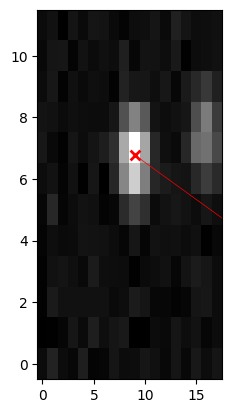

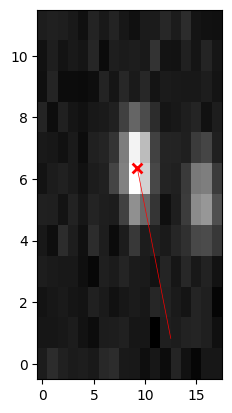

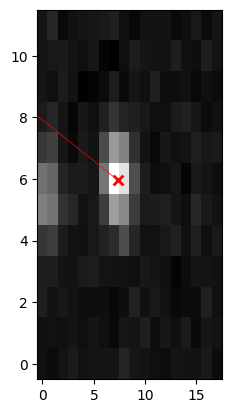

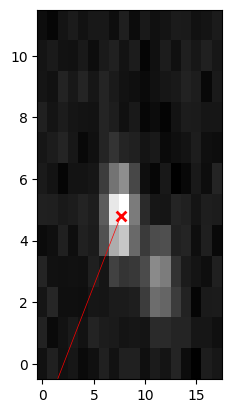

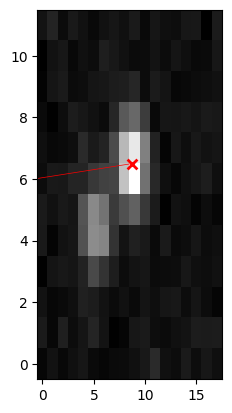

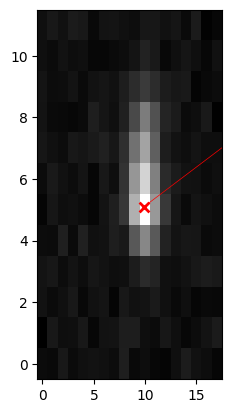

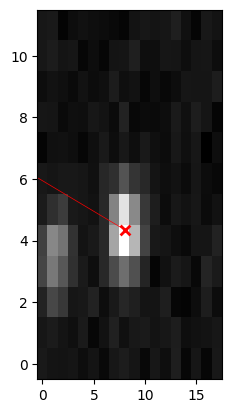

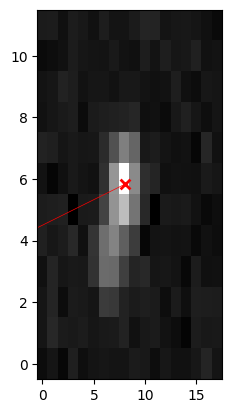

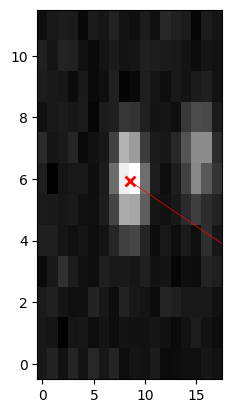

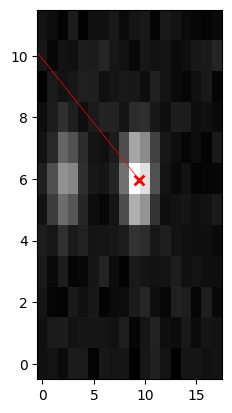

In [5]:
w0, z0 = 0.5 * (Nw - 1.), 0.5 * (Nz - 1.)
foo = np.array([1., 0.]) # arcsec
for j in range(10):
    plt.imshow(Y[j].T, origin="lower", interpolation="nearest", cmap="gray",
               aspect=3.)
    dw, dz = X["wz_offset"][j]
    plt.scatter(w0 + dw, z0 + dz, marker="x", c="r", s=50, lw=2)
    bar = rotscale(X["scan_angle"][j]) @ foo
    plt.plot([w0 + dw, w0 + dw + bar[0]], [z0 + dz, z0 + dz + bar[1]], "r-", lw=0.5)
    plt.xlim(-0.5, Nw - 0.5)
    plt.ylim(-0.5, Nz - 0.5)
    plt.show()

In [6]:
def make_many_datasets(N, dir=".", clobber=False):
    """
    ## inputs:
    - `N`: the number of datasets to make
    - `dir`: the directory to put them into
    - `clobber`: make all new files or just the ones that don't exist

    ## outputs:
    - data_00000.fits in the directory
    """
    seeds = np.arange(N)
    for seed in seeds:
        rng = np.random.default_rng(seed)
        x, y, true = make_one_toy_dataset(rng)
        fn = dir + "/" + f"data_{seed:005d}.fits"
        if (clobber or not os.path.exists(fn)):
            print("making file " + fn)
            with fits.open(fn, "append") as hdul:
                hdul.append(fits.PrimaryHDU(y))
                hdul.append(fits.BinTableHDU(x, name="x"))
                hdul.append(fits.BinTableHDU(true, name="true"))
        else:
            print("not making " + fn)

In [7]:
make_many_datasets(14, clobber=False)

not making ./data_00000.fits
not making ./data_00001.fits
not making ./data_00002.fits
not making ./data_00003.fits
not making ./data_00004.fits
not making ./data_00005.fits
not making ./data_00006.fits
not making ./data_00007.fits
not making ./data_00008.fits
not making ./data_00009.fits
not making ./data_00010.fits
not making ./data_00011.fits
not making ./data_00012.fits
not making ./data_00013.fits


In [8]:
def Jzeros(Nm, Nn):
    Jzeros = np.zeros([2 * Nm + 1, Nn])
    for m in np.arange(Nm):
        col = special.jn_zeros(m, Nn)
        Jzeros[Nm + m] = col
        Jzeros[Nm - m] = col
    return Jzeros

def W(Nm, Nn, rs, phis, R):
    ms_rav = np.ravel(np.ones(Nn)[None,:] * (np.arange(2 * Nm + 1)-Nm)[:,None])
    Jzeros_rav = np.ravel(Jzeros(Nm, Nn))
    samples = special.jv(np.abs(ms_rav[None,:]), Jzeros_rav[None,:] * rs[:,:,None] / R) * np.exp(1j * ms_rav[None,:] * phis[:,:,None])
    pixs = np.mean(np.mean(samples.reshape((Nw, 2, 6 * Nz, (2 * Nm + 1) * Nn)), 1).reshape((Nw, Nz, 6, (2 * Nm + 1) * Nn)), 2)
    W_fft = np.fft.fft2(pixs, axes=(0, 1))
    return samples, W_fft

In [35]:
R = ZPIXSCALE * Nz + WPIXSCALE
wgrid, zgrid = WPIXSCALE * (np.arange(2 * Nw) - 0.5 * (2 * Nw - 1.)), WPIXSCALE * (np.arange(6 * Nz) - 0.5 * (6 * Nz - 1.))
rs = np.sqrt(wgrid[:,None]**2 + zgrid[None,:]**2)
phis = np.atan2(zgrid[None,:], wgrid[:,None])
Nm = 70
Nn = 70

samples_test, W_test = W(Nm, Nn, rs, phis, R)
W_test_big = W_test.reshape(Nw * Nz, (2 * Nm + 1) * Nn)
W_inv = (np.linalg.lstsq(W_test_big.conj().T @ W_test_big, np.identity((2 * Nm + 1) * Nn, dtype="complex128"))[0] @ W_test_big.conj().T)

In [38]:
def besselize(Nm_im, Nn_im, rs, phis, R):
    ms_rav = np.ravel(np.ones(Nn_im)[None,:] * (np.arange(2 * Nm_im + 1)-Nm_im)[:,None])
    Jzeros_rav = np.ravel(Jzeros(Nm_im, Nn_im))
    samples = special.jv(np.abs(ms_rav[None,:]), Jzeros_rav[None,:] * rs[:,:,None] / R) * np.exp(1j * ms_rav[None,:] * phis[:,:,None])
    return samples

In [39]:
R = ZPIXSCALE * Nz + WPIXSCALE
Nr = R // WPIXSCALE
xgrid, ygrid = (WPIXSCALE / 2) * (np.arange(4 * Nr) - 0.5 * (4 * Nr - 1.)), (WPIXSCALE / 2) * (np.arange(4 * Nr) - 0.5 * (4 * Nr - 1.))
rs_grid = np.sqrt(xgrid[:,None]**2 + ygrid[None,:]**2)
rs_im = np.where(rs_grid < R, rs_grid, np.nan)
phis_grid = np.atan2(ygrid[None,:], xgrid[:,None])
phis_im = np.where(rs_grid < R, phis_grid, np.nan)
Nm_lite = 10
Nn_lite = 20
#image_op = besselize(Nm, Nn, rs_im, phis_im, R)
image_op_lite = besselize(Nm_lite, Nn_lite, rs_im, phis_im, R)

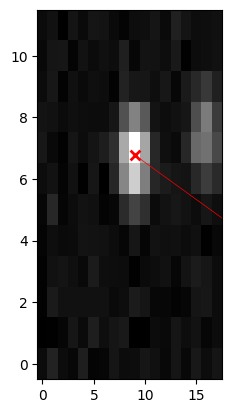

In [40]:
plt.imshow(Y[0].T, origin="lower", interpolation="nearest", cmap="gray",
               aspect=3.)
dw, dz = X["wz_offset"][0]
plt.scatter(w0 + dw, z0 + dz, marker="x", c="r", s=50, lw=2)
bar = rotscale(X["scan_angle"][0]) @ foo
plt.plot([w0 + dw, w0 + dw + bar[0]], [z0 + dz, z0 + dz + bar[1]], "r-", lw=0.5)
plt.xlim(-0.5, Nw - 0.5)
plt.ylim(-0.5, Nz - 0.5)
plt.show()

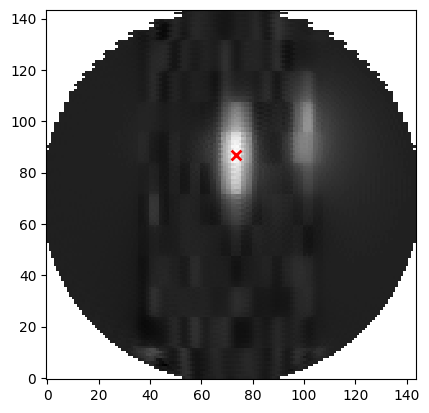

In [41]:
y_0 = np.ravel(np.fft.fft2(Y[0]))
a_test = W_inv @ y_0
x0, y0 = 0.5 * (4 * Nr - 1.), 0.5 * (4 * Nr - 1.)
dx = 4 * dw
dy = 12 * dz
plt.imshow(np.real(image_op @ a_test).T, origin="lower", interpolation="nearest", cmap="gray")
plt.scatter(x0 + dx, y0 + dy, marker="x", c="r", s=50, lw=2)
plt.show()

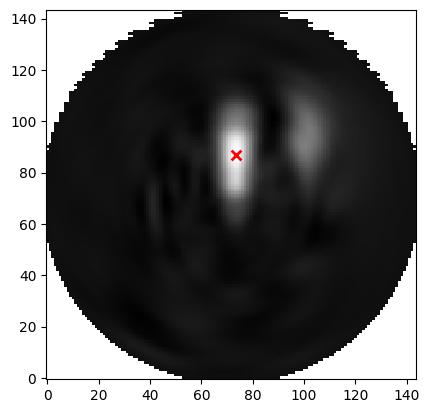

In [54]:
a_test_lite = np.ravel(a_test.reshape(2*Nm+1, Nn)[Nm-Nm_lite:Nm+Nm_lite+1,:Nn_lite])
plt.imshow(np.real(image_op_lite @ a_test_lite).T, origin="lower", interpolation="nearest", cmap="gray")
plt.scatter(x0 + dx, y0 + dy, marker="x", c="r", s=50, lw=2)
plt.show()

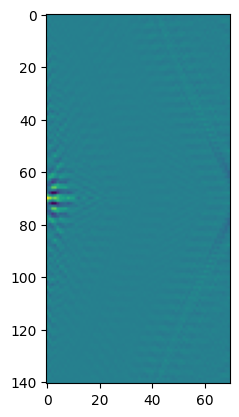

In [43]:
plt.imshow(np.real(a_test.reshape(2*Nm+1, Nn)))
plt.show()

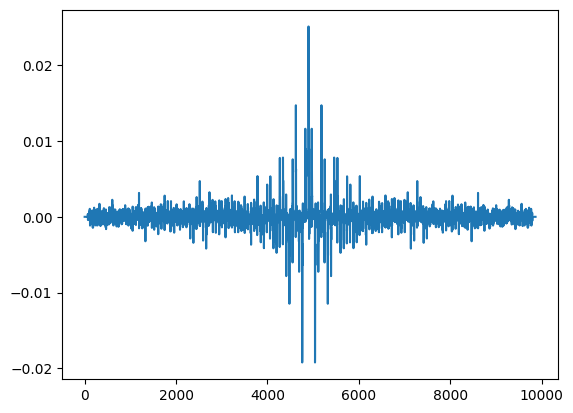

In [44]:
plt.plot(np.real(a_test))
plt.show()

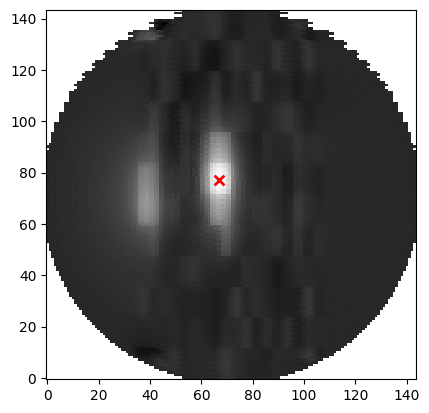

In [45]:
y_2 = np.ravel(np.fft.fft2(Y[2]))
a_test2 = W_inv @ y_2
dw2, dz2 = X["wz_offset"][2]
dx2 = 4 * dw2
dy2 = 12 * dz2
plt.imshow(np.real(image_op @ a_test2).T, origin="lower", interpolation="nearest", cmap="gray")
plt.scatter(x0 + dx2, y0 + dy2, marker="x", c="r", s=50, lw=2)
plt.show()

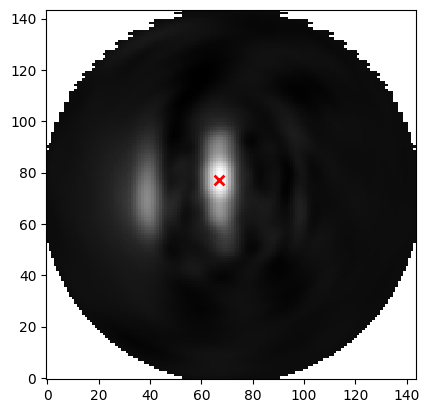

In [46]:
a_test_lite2 = np.ravel(a_test2.reshape(2*Nm+1, Nn)[Nm-Nm_lite:Nm+Nm_lite+1,:Nn_lite])
plt.imshow(np.real(image_op_lite @ a_test_lite2).T, origin="lower", interpolation="nearest", cmap="gray")
plt.scatter(x0 + dx2, y0 + dy2, marker="x", c="r", s=50, lw=2)
plt.show()

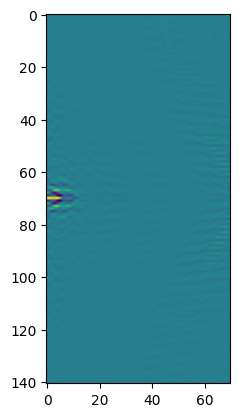

In [47]:
plt.imshow(np.real(a_test2.reshape(2*Nm+1, Nn)))
plt.show()

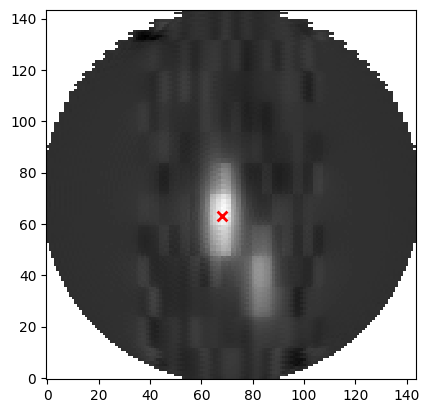

In [48]:
y_3 = np.ravel(np.fft.fft2(Y[3]))
a_test3 = W_inv @ y_3
dw3, dz3 = X["wz_offset"][3]
dx3 = 4 * dw3
dy3 = 12 * dz3
plt.imshow(np.real(image_op @ a_test3).T, origin="lower", interpolation="nearest", cmap="gray")
plt.scatter(x0 + dx3, y0 + dy3, marker="x", c="r", s=50, lw=2)
plt.show()

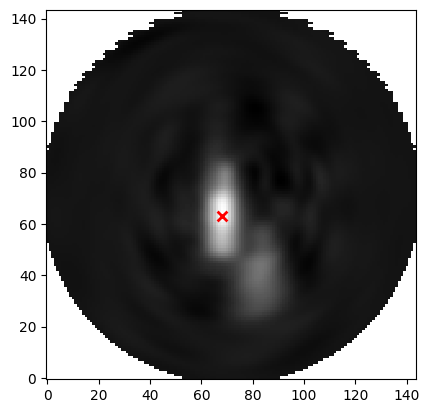

In [49]:
a_test_lite3 = np.ravel(a_test3.reshape(2*Nm+1, Nn)[Nm-Nm_lite:Nm+Nm_lite+1,:Nn_lite])
plt.imshow(np.real(image_op_lite @ a_test_lite3).T, origin="lower", interpolation="nearest", cmap="gray")
plt.scatter(x0 + dx3, y0 + dy3, marker="x", c="r", s=50, lw=2)
plt.show()

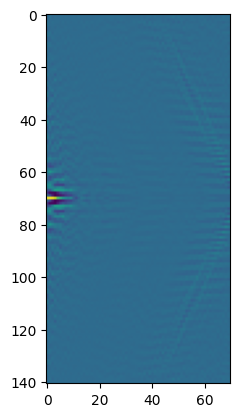

In [51]:
plt.imshow(np.real(a_test3.reshape(2*Nm+1, Nn)))
plt.show()